In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from ucimlrepo import fetch_ucirepo

In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

In [4]:
glass = fetch_ucirepo(id=42)

X = glass.data.features
y = glass.data.targets.squeeze()   # Series

df = X.copy()
df['Type'] = y
print(df.head())
print(df.info())
print("\nРаспределение классов:")
print(df['Type'].value_counts().sort_index())

        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0     1
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0     1
<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB
None

Распределение к

Пропуски:
 RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64


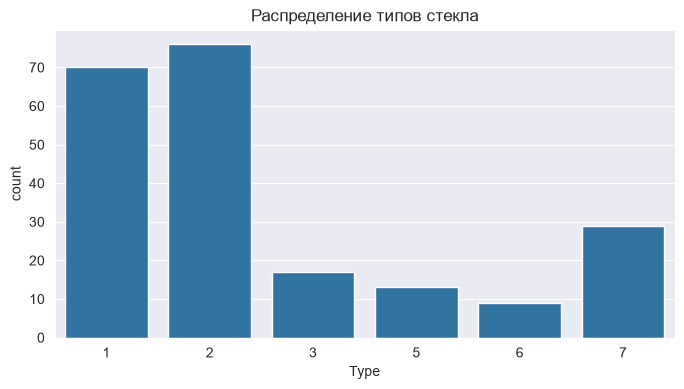

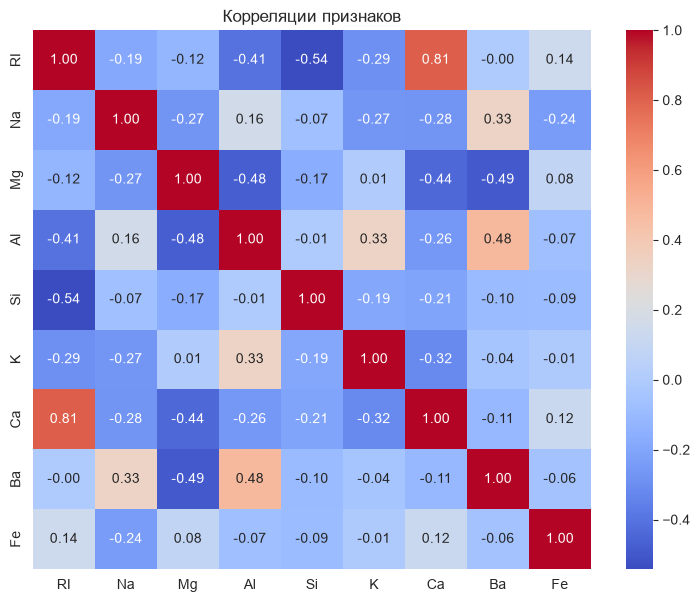

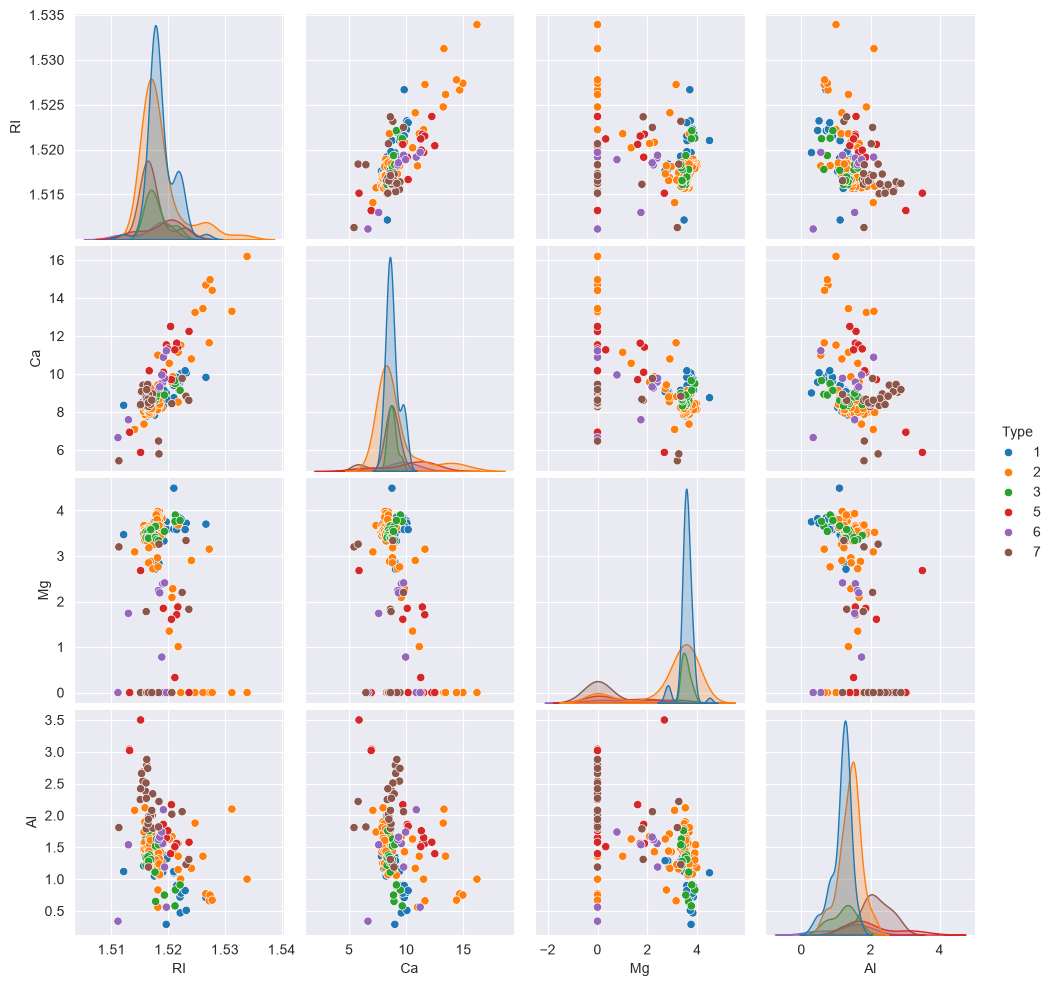

In [5]:
print("Пропуски:\n", df.isna().sum())

plt.figure(figsize=(8, 4))
sns.countplot(x='Type', data=df, order=sorted(df['Type'].unique()))
plt.title('Распределение типов стекла')
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns='Type').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляции признаков')
plt.show()

sns.pairplot(df, vars=['RI', 'Ca', 'Mg', 'Al'], hue='Type', palette='tab10')
plt.show()

In [6]:
X_feat = df.drop(columns='Type')
y_cls = df['Type']

X_train, X_test, y_train, y_test = train_test_split(
    X_feat, y_cls,
    test_size=0.25,
    random_state=42,
    stratify=y_cls
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("\nTrain классы:\n", y_train.value_counts().sort_index())
print("\nTest классы:\n", y_test.value_counts().sort_index())

Train: (160, 9), Test: (54, 9)

Train классы:
 Type
1    52
2    57
3    13
5    10
6     7
7    21
Name: count, dtype: int64

Test классы:
 Type
1    18
2    19
3     4
5     3
6     2
7     8
Name: count, dtype: int64


 k  accuracy  macro_f1  weighted_f1
 1  0.740741  0.707801     0.742243
 2  0.796296  0.714235     0.783830
 3  0.796296  0.681614     0.776572
 4  0.740741  0.615705     0.713248
 5  0.740741  0.608761     0.713114
 6  0.685185  0.628968     0.661817
 7  0.722222  0.645689     0.695924
 8  0.740741  0.675188     0.715873
 9  0.722222  0.618797     0.694709
10  0.740741  0.646642     0.713987
11  0.703704  0.546575     0.675573
12  0.685185  0.476955     0.654852
13  0.685185  0.463370     0.655803
14  0.666667  0.452507     0.633100
15  0.666667  0.466270     0.632848
16  0.666667  0.469203     0.639348
17  0.703704  0.479888     0.661597
18  0.666667  0.463636     0.627890
19  0.685185  0.393651     0.627690
20  0.666667  0.385656     0.611119


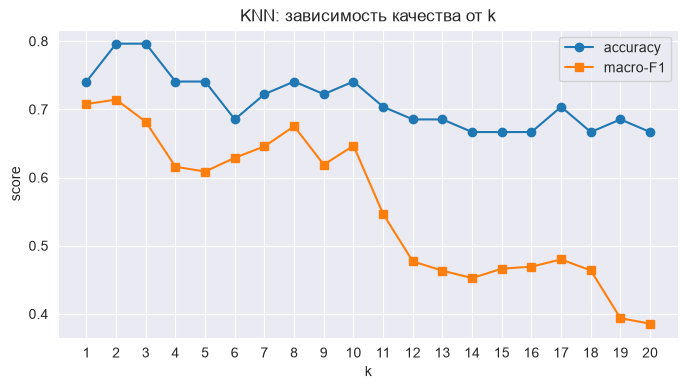

Лучший k по macro-F1: 2


In [7]:
k_values = list(range(1, 21))
knn_results = []

for k in k_values:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    knn_results.append({
        'k': k,
        'accuracy': accuracy_score(y_test, y_pred),
        'macro_f1': f1_score(y_test, y_pred, average='macro'),
        'weighted_f1': f1_score(y_test, y_pred, average='weighted')
    })

knn_df = pd.DataFrame(knn_results)
print(knn_df.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(knn_df['k'], knn_df['accuracy'], marker='o', label='accuracy')
plt.plot(knn_df['k'], knn_df['macro_f1'], marker='s', label='macro-F1')
plt.xlabel('k'); plt.ylabel('score'); plt.xticks(k_values)
plt.title('KNN: зависимость качества от k')
plt.legend(); plt.grid(True); plt.show()

best_k = int(knn_df.loc[knn_df['macro_f1'].idxmax(), 'k'])
print(f"Лучший k по macro-F1: {best_k}")

In [9]:
svm_results = []

for kernel in ['linear', 'rbf']:
    for C in [0.1, 1, 10, 100]:
        for gamma in (['scale', 'auto'] if kernel == 'rbf' else [None]):
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('svm', SVC(kernel=kernel, C=C,
                            gamma=gamma if gamma else 'scale',
                            class_weight='balanced'))
            ])
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)
            svm_results.append({
                'kernel': kernel, 'C': C, 'gamma': gamma,
                'accuracy': accuracy_score(y_test, y_pred),
                'macro_f1': f1_score(y_test, y_pred, average='macro')
            })

svm_df = pd.DataFrame(svm_results).sort_values('macro_f1', ascending=False)
print(svm_df.to_string(index=False))

kernel     C gamma  accuracy  macro_f1
   rbf  10.0 scale  0.777778  0.778479
   rbf  10.0  auto  0.777778  0.778479
   rbf 100.0 scale  0.759259  0.745344
   rbf 100.0  auto  0.759259  0.745344
linear 100.0   NaN  0.685185  0.722876
linear  10.0   NaN  0.666667  0.718511
linear   1.0   NaN  0.592593  0.673497
   rbf   1.0 scale  0.685185  0.663146
   rbf   1.0  auto  0.685185  0.663146
linear   0.1   NaN  0.537037  0.601407
   rbf   0.1 scale  0.537037  0.432702
   rbf   0.1  auto  0.537037  0.432702


In [10]:
tree_results = []

for criterion in ['gini', 'entropy']:
    for max_depth in [3, 5, 7, 10, None]:
        for min_samples_leaf in [1, 3, 5]:
            pipe = Pipeline([
                ('scaler', StandardScaler()),   # для дерева не обязательно, но не мешает
                ('tree', DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    class_weight='balanced',
                    random_state=42))
            ])
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)
            tree_results.append({
                'criterion': criterion, 'max_depth': max_depth,
                'min_samples_leaf': min_samples_leaf,
                'accuracy': accuracy_score(y_test, y_pred),
                'macro_f1': f1_score(y_test, y_pred, average='macro')
            })

tree_df = pd.DataFrame(tree_results).sort_values('macro_f1', ascending=False)
print(tree_df.head(10).to_string(index=False))

criterion  max_depth  min_samples_leaf  accuracy  macro_f1
     gini        3.0                 5  0.722222  0.728474
     gini        7.0                 5  0.666667  0.708998
     gini        NaN                 5  0.666667  0.708998
     gini       10.0                 5  0.666667  0.708998
  entropy        3.0                 1  0.722222  0.689332
     gini        3.0                 3  0.703704  0.678520
     gini        3.0                 1  0.703704  0.678520
  entropy        3.0                 3  0.703704  0.675287
     gini        5.0                 5  0.611111  0.667101
  entropy        NaN                 5  0.685185  0.663463


In [11]:
best_tree = DecisionTreeClassifier(
    criterion='entropy', max_depth=5, min_samples_leaf=1,
    class_weight='balanced', random_state=42
)
best_tree.fit(X_train, y_train)
print(export_text(best_tree, feature_names=list(X_train.columns)))

|--- Mg <= 2.70
|   |--- K <= 0.09
|   |   |--- Ba <= 0.20
|   |   |   |--- RI <= 1.52
|   |   |   |   |--- class: 6
|   |   |   |--- RI >  1.52
|   |   |   |   |--- class: 2
|   |   |--- Ba >  0.20
|   |   |   |--- Ca <= 8.37
|   |   |   |   |--- class: 7
|   |   |   |--- Ca >  8.37
|   |   |   |   |--- class: 7
|   |--- K >  0.09
|   |   |--- Na <= 14.20
|   |   |   |--- Al <= 1.47
|   |   |   |   |--- Na <= 12.12
|   |   |   |   |   |--- class: 7
|   |   |   |   |--- Na >  12.12
|   |   |   |   |   |--- class: 2
|   |   |   |--- Al >  1.47
|   |   |   |   |--- Ca <= 12.74
|   |   |   |   |   |--- class: 5
|   |   |   |   |--- Ca >  12.74
|   |   |   |   |   |--- class: 2
|   |   |--- Na >  14.20
|   |   |   |--- Ca <= 10.64
|   |   |   |   |--- class: 7
|   |   |   |--- Ca >  10.64
|   |   |   |   |--- class: 2
|--- Mg >  2.70
|   |--- Ca <= 8.32
|   |   |--- Mg <= 3.35
|   |   |   |--- class: 7
|   |   |--- Mg >  3.35
|   |   |   |--- Al <= 1.25
|   |   |   |   |--- class: 1
|   | 

In [12]:
rf_results = []

for n_estimators in [100, 300, 500]:
    for max_depth in [5, 10, None]:
        for min_samples_leaf in [1, 3]:
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('rf', RandomForestClassifier(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    class_weight='balanced',
                    random_state=42,
                    n_jobs=-1))
            ])
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)
            rf_results.append({
                'n_estimators': n_estimators, 'max_depth': max_depth,
                'min_samples_leaf': min_samples_leaf,
                'accuracy': accuracy_score(y_test, y_pred),
                'macro_f1': f1_score(y_test, y_pred, average='macro')
            })

rf_df = pd.DataFrame(rf_results).sort_values('macro_f1', ascending=False)
print(rf_df.head(10).to_string(index=False))

 n_estimators  max_depth  min_samples_leaf  accuracy  macro_f1
          500       10.0                 1  0.814815  0.785714
          100       10.0                 1  0.796296  0.783241
          100        NaN                 1  0.796296  0.783241
          300        NaN                 1  0.814815  0.774043
          500        NaN                 1  0.814815  0.774043
          300       10.0                 1  0.814815  0.774043
          300       10.0                 3  0.759259  0.731881
          300        5.0                 1  0.759259  0.721102
          500       10.0                 3  0.740741  0.717921
          300        NaN                 3  0.740741  0.717921


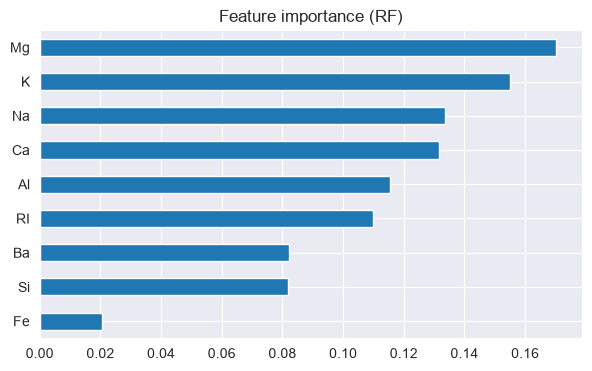

In [13]:
best_rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=1,
    class_weight='balanced', random_state=42, n_jobs=-1
)
best_rf.fit(X_train, y_train)

imp = pd.Series(best_rf.feature_importances_, index=X_train.columns)
imp.sort_values().plot(kind='barh', figsize=(7, 4), title='Feature importance (RF)')
plt.show()

In [14]:
def summarize(name, results_df, **best_params):
    best = results_df.iloc[0]
    return {
        'model': name,
        'best_params': best_params,
        'accuracy': best['accuracy'],
        'macro_f1': best['macro_f1']
    }

summary = pd.DataFrame([
    summarize('KNN', knn_df, k=best_k),
    summarize('SVM', svm_df, kernel=svm_df.iloc[0]['kernel'],
              C=svm_df.iloc[0]['C'], gamma=svm_df.iloc[0]['gamma']),
    summarize('DecisionTree', tree_df,
              criterion=tree_df.iloc[0]['criterion'],
              max_depth=tree_df.iloc[0]['max_depth'],
              min_samples_leaf=tree_df.iloc[0]['min_samples_leaf']),
    summarize('RandomForest', rf_df,
              n_estimators=rf_df.iloc[0]['n_estimators'],
              max_depth=rf_df.iloc[0]['max_depth'],
              min_samples_leaf=rf_df.iloc[0]['min_samples_leaf'])
])
print(summary.to_string(index=False))

       model                                                         best_params  accuracy  macro_f1
         KNN                                                            {'k': 2}  0.740741  0.707801
         SVM                      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}  0.777778  0.778479
DecisionTree      {'criterion': 'gini', 'max_depth': 3.0, 'min_samples_leaf': 5}  0.722222  0.728474
RandomForest {'n_estimators': 500.0, 'max_depth': 10.0, 'min_samples_leaf': 1.0}  0.814815  0.785714


              precision    recall  f1-score   support

           1      0.938     0.833     0.882        18
           2      0.875     0.737     0.800        19
           3      0.500     0.750     0.600         4
           5      0.750     1.000     0.857         3
           6      0.400     1.000     0.571         2
           7      1.000     0.875     0.933         8

    accuracy                          0.815        54
   macro avg      0.744     0.866     0.774        54
weighted avg      0.862     0.815     0.827        54



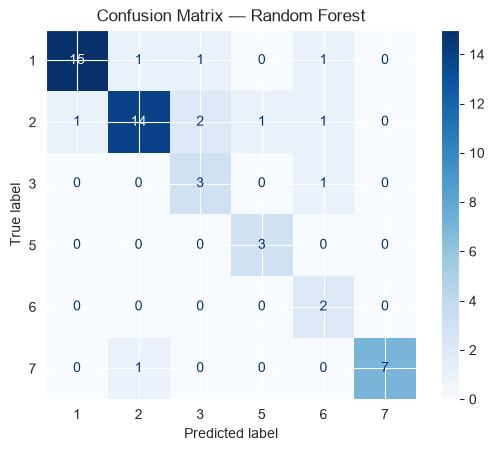

In [15]:
final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=1,
        class_weight='balanced', random_state=42, n_jobs=-1))
])
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))

labels = sorted(y_cls.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix — Random Forest')
plt.show()